# Projet Open Food Facts : Analyse, Nettoyage et Équilibrage du Dataset

Ce projet s'appuie sur un jeu de données extrait de la base globale publique **Open Food Facts**.

### Origine du Dataset
Le dataset utilisé provient de la plateforme **Kaggle** et est accessible via le lien suivant :
[Food Detailed Nutritional Content on Kaggle](https://www.kaggle.com/datasets/alexandrelemercier/food-detailed-nutritional-content?select=openfoodfacts_cleaned.csv)

#### Description officielle (Kaggle) :
> *"Ce jeu de données Open Food Facts est une collection exhaustive dérivée de la base de données Open Food Facts originale. Cette version allégée conserve les informations essentielles tout en réduisant sa taille de 9 Go à 400 Mo. Elle comprend des données sur environ 2 millions de produits alimentaires du monde entier (principalement de France et des États-Unis). Ce jeu de données est une excellente ressource pour quiconque souhaite mieux comprendre l'impact nutritionnel et environnemental d'une grande variété de produits alimentaires. Il peut contribuer à faire de meilleurs choix alimentaires et à adopter des habitudes alimentaires plus saines. En particulier, 11 des caractéristiques les plus utiles ne contiennent aucune valeur manquante."*

---

### Dictionnaire des Colonnes et Signification :
*   `product_name` : Le nom du produit.
*   `generic_name` : Nom général ou description du produit.
*   `quantity` : La quantité du produit dans son emballage (ex. « 500 g », « 1 L »).
*   `brands` : La ou les marques qui produisent le produit.
*   `categories_en` : Catégories auxquelles appartient le produit, en anglais.
*   `origins_en` : Pays d'origine des ingrédients, en anglais.
*   `countries_en` : Pays où le produit est vendu, en anglais.
*   `traces_en` : Traces potentielles d'allergènes (ex. : « traces d'arachides »).
*   `additives_n` : Nombre d'additifs présents dans le produit.
*   `additives_en` : Liste des additifs présents dans le produit, en anglais.
*   `nutriscore_score` : Le Nutri-Score du produit (note allant de -15 à +40).
*   `food_groups_en` : Classification des groupes alimentaires, en anglais.
*   `ecoscore_score` : L'éco-score du produit, qui mesure son impact environnemental.
*   `ecoscore_grade` : La note Eco-Score (de A à E) indiquant l'impact environnemental.
*   `main_category_en` : La catégorie principale du produit, en anglais.
*   `energy-kcal_100g` : Teneur en énergie en kilocalories pour 100 grammes.
*   `fat_100g` : Teneur totale en matières grasses pour 100 grammes.
*   `saturated-fat_100g` : Teneur en graisses saturées pour 100 grammes.
*   `monounsaturated-fat_100g` : Teneur en graisses mono-insaturées pour 100 grammes.
*   `polyunsaturated-fat_100g` : Teneur en graisses polyinsaturées pour 100 grammes.
*   `trans-fat_100g` : Teneur en gras trans pour 100 grammes.
*   `cholesterol_100g` : Teneur en cholestérol pour 100 grammes.
*   `carbohydrates_100g` : Teneur totale en glucides pour 100 grammes.
*   `sugars_100g` : Teneur en sucre pour 100 grammes.
*   `fiber_100g` : Teneur en fibres pour 100 grammes.
*   `proteins_100g` : Teneur en protéines pour 100 grammes.
*   `salt_100g` : Teneur en sel pour 100 grammes.
*   `sodium_100g` : Teneur en sodium pour 100 grammes.
*   `vitamin-a_100g` : Teneur en vitamine A pour 100 grammes.
*   `vitamin-d_100g` : Teneur en vitamine D pour 100 grammes.
*   `vitamin-c_100g` : Teneur en vitamine C pour 100 grammes.
*   `potassium_100g` : Teneur en potassium pour 100 grammes.
*   `calcium_100g` : Teneur en calcium pour 100 grammes.
*   `iron_100g` : Teneur en fer pour 100 grammes.
*   `fruits-vegetables-nuts-estimate-from-ingredients_100g` : Estimation de la teneur en fruits, légumes et noix pour 100g.
*   `nutrition-score-fr_100g` : Le Nutri-Score français brut pour 100 grammes, indiquant la qualité nutritionnelle globale.

---

## Étape 1 : Chargement des Données
Nous commençons par importer le dataset afin de faire un premier inventaire de sa taille et de ses types de colonnes.

In [100]:
import pandas as pd

# 1. Chargement du fichier CSV
file_path = './openfoodfacts_cleaned.csv'
df = pd.read_csv(file_path)

df = df.drop(columns=['Unnamed: 0']) # Index résiduel du au chargement initial du fichier

# Affichage des premières lignes
print("--- Aperçu des 5 premières lignes ---")
display(df.head())


/tmp/ipykernel_3864/589540815.py:5: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


--- Aperçu des 5 premières lignes ---


,product_name,generic_name,quantity,brands,categories_en,origins_en,countries_en,traces_en,additives_n,additives_en,...,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,potassium_100g,calcium_100g,iron_100g,fruits-vegetables-nuts-estimate-from-ingredients_100g,nutrition-score-fr_100g
0,Skyr,NaN,480 g,Danone,"Dairies,Fermented foods,Fermented milk product...",NaN,France,NaN,NaN,NaN,...,10.0,0.09,0.036,NaN,NaN,NaN,NaN,NaN,NaN,-5.0
1,Vitória crackers,NaN,NaN,NaN,NaN,NaN,France,NaN,NaN,NaN,...,7.8,1.40,0.560,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Hamburguesas de ternera 100%,NaN,NaN,NaN,NaN,NaN,Spain,NaN,NaN,NaN,...,15.7,2.10,0.840,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Blueberry Cobbler Coffee,NaN,NaN,NaN,NaN,NaN,United States,NaN,NaN,NaN,...,0.0,0.00,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Sauce Sweety chili 0%,NaN,NaN,NaN,NaN,NaN,France,NaN,NaN,NaN,...,0.2,2.04,0.816,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Pour de l'**apprentissage supervisé**, non devons choisir le label de nos données. Pour nous, ce sera les catégories de Nutri-Score A,B,C,d et E qu'on calcule à partir des valeurs de Nutri-Scores. Or, le jeu de données possède 2 features définies comme le Nutri-Score: **'nutriscore_score'** et **'nutrition-score-fr_100g'**. La différence n'étant pas évidente, on commence par comparer ces deux features.

In [101]:
cols_to_compare = ['nutriscore_score', 'nutrition-score-fr_100g']

print("\n--- Taux de valeurs manquantes (NaN) ---")
print(df[['nutriscore_score', 'nutrition-score-fr_100g']].isna().sum())

# On filtre les lignes où au moins l'une des deux est renseignée (car 2 NaN sont comptés différents)
df_compare = df[df['nutriscore_score'].notna() | df['nutrition-score-fr_100g'].notna()]

# Différence stricte entre les deux colonnes (en excluant les NaN)
diff_mask = df_compare['nutriscore_score'] != df_compare['nutrition-score-fr_100g']
diff_count = diff_mask.sum()

print(f"\nNombre de lignes où les valeurs diffèrent (hors NaN) : {diff_count}")

if diff_count > 0:
    print("\nExemples de différences :")
    display(df_compare[diff_mask][cols_to_compare].head())
else:
    print("\nLes deux colonnes sont identiques sur tous le dataset. Colonne `nutriscore_score` supprimée !")
    # Suppression de la colonne "nutriscore_score"
    df = df.drop(columns="nutriscore_score")



--- Taux de valeurs manquantes (NaN) ---
nutriscore_score           963857
nutrition-score-fr_100g    963857
dtype: int64

Nombre de lignes où les valeurs diffèrent (hors NaN) : 0

Les deux colonnes sont identiques sur tous le dataset. Colonne `nutriscore_score` supprimée !


Nous allons maintenant manipuler certaines valeurs absurdes. Tout d'abord, certaines lignes possèdent plus de 100g de nutriments pour 100g de ce produit consommés. Nous supprimons ces lignes non pas pour toutes les features mais seulement pour celles que nous allons garder pour l'entraînement de notre modèle car ces erreurs absurdes issues de simples fautes de frappe n'influent pas les autres données du produit. Ainsi, on ne voudrait pas perdre une donnée précieuse d'entraînement car elle présente une unique valeur incohérente pour une feature qu'on supprime pendant le preprocessing.

In [102]:
import numpy as np

# Limiter les nutriments à 100 g, car les valeurs sont indiquées pour 100 g de produit alimentaire
mask_unconsistent_values = (
    (df['fat_100g'] > 100) |
    (df['saturated-fat_100g'] > 100) |
    (df['carbohydrates_100g'] > 100) |
    (df['sugars_100g'] > 100) |
    (df['fiber_100g'] > 100) |
    (df['proteins_100g'] > 100) |
    (df['salt_100g'] > 100) |
    (df['fruits-vegetables-nuts-estimate-from-ingredients_100g'] > 100)
)

nb_valeurs_absurdes = len(df[mask_unconsistent_values])
df = df[~mask_unconsistent_values]
print(f"Nombre de lignes supprimées : {nb_valeurs_absurdes}")

# Correction des valeurs incohérentes pour les carbohydrates
df['carbohydrates_100g'] = np.maximum(df['carbohydrates_100g'], df['sugars_100g'])


Nombre de lignes supprimées : 2617


## Étape 2 : Filtrage Géographique (Focus sur la France)
L'objectif est d'étudier le marché de consommation français. Nous filtrons donc le dataset pour ne retenir que les produits vendus en France (`countries_en == 'France'`). Cela réduit le volume de données et améliore la pertinence de l'étude locale.

In [103]:
# 2. Filtrage pour l'arrivage / vente en France uniquement
df_france = df[df['countries_en'] == 'France']
print(f"Filtrage effectué sur la colonne 'countries_en' pour la valeur 'France'")

print(f"Nombre de lignes après filtrage : {df_france.shape[0]}")

Filtrage effectué sur la colonne 'countries_en' pour la valeur 'France'
Nombre de lignes après filtrage : 641545


## Étape 3 : Exclusion des boissons
Le Nutri-Score n'utilise pas les mêmes seuils de classes pour les boissons et pour les aliments : les tranches de score qui définissent les classes A à E sont différentes, et la classe A y est réservée à l'eau. Notre fonction de classification (tranches des aliments) donnerait donc des étiquettes erronées pour les boissons (par exemple, l'eau, de score 0, serait classée B au lieu de A).
Comme ces étiquettes servent aussi à équilibrer le jeu de données (Étapes 8 à 11), nous excluons les boissons dès maintenant, avant de calculer les classes. Elles sont repérées par leur groupe alimentaire (`food_groups_en` commençant par `Beverages`).
**Limite :** le modèle final ne couvre pas les boissons. Les produits dont le groupe alimentaire n'est pas renseigné ne peuvent pas être identifiés comme boissons et sont conservés.

In [104]:
masque_boissons = df_france['food_groups_en'].fillna('').str.startswith('Beverages')
print(f"Boissons exclues : {masque_boissons.sum()} lignes ({masque_boissons.mean()*100:.2f}% des produits vendus en France)")
df_france = df_france[~masque_boissons]
print(f"Nombre de lignes après exclusion des boissons : {df_france.shape[0]}")

Boissons exclues : 20240 lignes (3.15% des produits vendus en France)
Nombre de lignes après exclusion des boissons : 621305


## Étape 4 : Filtrage et Analyse Fondamentale des Notes Nutritionnelles

Dans cette étape, nous commençons par filtrer les données sans Nutri-Score car nous ne pourrons pas les utiliser pour l'entraînement. Ensuite, nous allons calculer la distribution des variables cibles d'impact de notre étude. Nous récupérons la valeur brute du Nutri-Score (feature **'nutrition-score-fr_100g'** allant de **-15** à **+40**) pour la classer en **5 catégories de A à E**.

Cette classification respecte la règle officielle du Nutri-Score en France :
*   **Catégorie A** : Si le score est compris entre **-15 et -1** inclus.
*   **Catégorie B** : Si le score est compris entre **0 et 2** inclus.
*   **Catégorie C** : Si le score est compris entre **3 et 10** inclus.
*   **Catégorie D** : Si le score est compris entre **11 et 18** inclus.
*   **Catégorie E** : Si le score est compris entre **19 et 40** inclus.

Nous analysons ensuite la distribution et le pourcentage de chaque score et catégorie sur notre jeu de données.

In [105]:
# ==========================================
# 1. ANALYSE DU NUTRI-SCORE (VALEURS DE -15 À +40)
# ==========================================

nutri_col = 'nutrition-score-fr_100g' #

# Filtrage des lignes non labelisées (= sans Nutri-Score renseigné)
df_france_nutri_valide = df_france[df_france[nutri_col].notna()]
print("Nombre de lignes du dataset après filtrage des produits non labelisés:", df_france_nutri_valide.shape[0])

# Pour chaque valeur unique de score (de -15 à 40), on compte le nombre de produits (lignes)
score_counts = df_france_nutri_valide[nutri_col].value_counts().sort_index()

# Nous calculons ensuite la proportion que représente chaque score sur le total
# On multiplie par 100 pour obtenir des valeurs en %
score_pcts = (df_france_nutri_valide[nutri_col].value_counts(normalize=True) * 100).sort_index()

# Création d'un tableau synthétique pour afficher les effectifs et les pourcentages par valeur de score
df_detailed_scores = pd.DataFrame({
    'Nombre de lignes': score_counts,
    'Pourcentage (%)': score_pcts.round(2)
})

print("--- Répartition détaillée du score nutritionnel (-15 à +40) ---")
display(df_detailed_scores)

# ==========================================
# 2. REGROUPEMENT DU NUTRI-SCORE EN 5 CATÉGORIES (A, B, C, D, E)
# ==========================================

# Définition de la fonction de classification selon les tranches demandées
def attribuer_categorie(score):
    if -15 <= score <= -1:
        return 'A'
    elif 0 <= score <= 2:
        return 'B'
    elif 3 <= score <= 10:
        return 'C'
    elif 11 <= score <= 18:
        return 'D'
    elif 19 <= score <= 40:
        return 'E'
    return np.nan

# Application de la fonction pour créer une nouvelle colonne contenant la catégorie A, B, C, D ou E
df_france_nutri_valide['nutriscore_categorie'] = df_france_nutri_valide[nutri_col].apply(attribuer_categorie)

# Comptage des effectifs et des pourcentages pour chaque catégorie créée (même méthode qu'au-dessus)
cat_counts = df_france_nutri_valide['nutriscore_categorie'].value_counts().sort_index()
cat_pcts = (df_france_nutri_valide['nutriscore_categorie'].value_counts(normalize=True) * 100).sort_index()

# Assemblage des résultats dans un tableau récapitulatif pour le Nutri-Score
df_nutri_categories = pd.DataFrame({
    'Nombre de lignes': cat_counts,
    'Pourcentage (%)': cat_pcts.round(2)
})

print("\n--- Tableau récapitulatif par catégorie Nutri-Score (A à E) ---")
display(df_nutri_categories)

Nombre de lignes du dataset après filtrage des produits non labelisés: 305585
--- Répartition détaillée du score nutritionnel (-15 à +40) ---


,Nombre de lignes,Pourcentage (%)
nutrition-score-fr_100g,,
-15.0,2,0.00
-14.0,19,0.01
-13.0,54,0.02
-12.0,216,0.07
-11.0,380,0.12
-10.0,359,0.12
-9.0,479,0.16
-8.0,713,0.23
-7.0,1037,0.34



--- Tableau récapitulatif par catégorie Nutri-Score (A à E) ---


/tmp/ipykernel_3864/2182256521.py:46: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_france_nutri_valide['nutriscore_categorie'] = df_france_nutri_valide[nutri_col].apply(attribuer_categorie)


,Nombre de lignes,Pourcentage (%)
nutriscore_categorie,,
A,45830,15.00
B,39772,13.02
C,64081,20.97
D,101290,33.15
E,54612,17.87


Après cette étape, le dataset possède maintenant **305 585 lignes**, et tous les produits sont labelisés. La catégorie de Nutri-Score avec le moins d'éléments est la **B avec 39 772 produits**, un nombre suffisamment grand pour que notre étude statistique soit pertinente, donc nous pouvons valider cette répartition des Nutri-Scores en 5 catégories.

## Étape 5 : Analyse des Valeurs Manquantes Post-Filtrage
Maintenant que nous nous concentrons uniquement sur la **France et sur les produits ayant un Nutri-Score renseigné**, nous réévaluons le taux de données manquantes (NaN) par colonne.

In [106]:
print("--- Nombre de valeurs manquantes (NaN) par colonne pour le jeu de données France avec Nutri-Score renseigné ---")
print(f"Taille du sous-ensemble : {df_france_nutri_valide.shape[0]} lignes\n")

# Calcul du nombre de NaN
nan_counts_sub = df_france_nutri_valide.isna().sum().to_frame(name='Nombre de NaN')

# Calcul du pourcentage par rapport à ce sous-ensemble
nan_counts_sub['Pourcentage (%)'] = ((df_france_nutri_valide.isna().sum() / len(df_france_nutri_valide)) * 100).round(2)

display(nan_counts_sub)


--- Nombre de valeurs manquantes (NaN) par colonne pour le jeu de données France avec Nutri-Score renseigné ---
Taille du sous-ensemble : 305585 lignes



,Nombre de NaN,Pourcentage (%)
product_name,0,0.00
generic_name,258151,84.48
quantity,145642,47.66
brands,80940,26.49
categories_en,0,0.00
origins_en,270593,88.55
countries_en,0,0.00
traces_en,250585,82.00
additives_n,154266,50.48
additives_en,223631,73.18


De nombreuses features possèdent près de 100% de valeurs non définies. Nous devons donc maintenant trier les features de notre jeu de données pour optimiser l'entraînement de notre modèle.

## Étape 6 : Nettoyage Dimensionnel et Suppression de Colonnes
A cette étape, nous décidons de supprimer un ensemble de colonnes afin d'optimiser le modèle. Différentes raisons justifient nos choix, dont voici le détail:

#### 1. Taux de NaN critique > 98-99%:
*   `vitamin-a_100g`, `vitamin-c_100g`, `potassium_100g`, `calcium_100g`, `iron_100g`: Ces variables présentent un taux de valeurs manquantes (NaN) extrêmement élevé sur le marché français, ce qui les rend inexploitables pour notre entraînement statistique.

#### 2. Informations textuelles secondaires, catégorielles lourdes ou redondantes
*   `generic_name` : Description textuelle trop variée, générique et redondante avec `product_name` ou les catégories.
*   `quantity` : Contient des formats de texte non normalisés (ex. "500g", "1 L") sans impact direct sur la qualité nutritionnelle.
*   `brands` : Donnée catégorielle à très haute cardinalité (des milliers de marques différentes), ce qui complexifierait inutilement les modèles de prédiction sans valeur ajoutée nutritionnelle directe.
*   `origins_en` : Pays d'origine des ingrédients. Très majoritairement non renseigné (88.64%) et textuel.
*   `traces_en` : Traces potentielles d'allergènes. Informations textuelles très incomplètes (82.62%) et non structurées.
*   `additives_en`,`additifs_n`: Les additifs présents dans un produit alimentaire n'ont aucun lien avec le calcul du Nutri-Score et peuvent même être trompeuses car certains produits contenants de nombreux additifs peuvent avoir un très bon Nutri-Score s'ils sont peu caloriques, ne contiennent que très peu de sucre... On empêche ainsi notre modèle de s'égarer.

#### 3. Détails de graisses secondaires ou spécifiques
*   `monounsaturated-fat_100g`, `polyunsaturated-fat_100g`, `trans-fat_100g` : Sous-catégories de lipides qui sont très peu renseignées, contrairement à la colonne globale `fat_100g` (matières grasses totales) et `saturated-fat_100g` (graisses saturées) que nous conservons.
*   `cholesterol_100g` : Taux de cholestérol, colonne quasiment vide en Europe car son affichage n'est pas obligatoire sur les étiquetages nutritionnels français (contrairement aux USA).

#### 4. Variables redondantes (Colinéarité parfaite)
*   `sodium_100g` : Le sel alimentaire (NaCl) est constitué à 40% de sodium et 60% de chlore d'où la relation `salt_100g` = 2.5 * `sodium_100g`. On peut  donc supprimer cette feature, qui ne contient aucune information supplémentaire.

#### 5. Indicateurs environnementaux hors sujet
*   `ecoscore_score`, `ecoscore_grade` : L'Éco-Score mesure l'impact environnemental du produit ce qui n'a aucun impact sur l'aspect nutritionnel (Nutri-Score) et peut même ajouter du bruit et détériorer le modèle. De plus, cet éco-score n'est pas renseigné pour un gros pourcentage de nos données.

#### 6. Variables catégorielles trop spécifiques et complexes à analyser (voir code cellule suivante)
* `categories_en`, `main_category_en`, `categories_en`, : Respectivement 42 380, 15 382 et 210 148 valeurs différentes, trop spécifiques pour la grande majorité des éléments. On pourrait garder seulement les catégories les plus importantes et regrouper les autres dans une catégorie 'autre' mais cette dernière serait, ici, trop importante.

#### 7. Pays de vente
* `countries_en` : A cette étape, tous les éléments présents possèdent la même valeur: France

In [107]:
df_france_nutri_valide[df_france_nutri_valide['generic_name'] == 'Pâtes alimentaires de qualité supérieure'][['generic_name','product_name']]


,generic_name,product_name
736139,Pâtes alimentaires de qualité supérieure,Vermicelles
782863,Pâtes alimentaires de qualité supérieure,Panzani etoiles 500g
782864,Pâtes alimentaires de qualité supérieure,Panzani alphabets 500g
782866,Pâtes alimentaires de qualité supérieure,Panzani pescadines
782867,Pâtes alimentaires de qualité supérieure,cheveux d'ange
...,...,...
1716576,Pâtes alimentaires de qualité supérieure,Fusilloni Al bronzo
1716599,Pâtes alimentaires de qualité supérieure,Barilla piccolini mini tortiglioni 500g
1716618,Pâtes alimentaires de qualité supérieure,Spaghetti quad 400g albronzo fr
1716630,Pâtes alimentaires de qualité supérieure,Barilla pates fusilli 500g+200g offert


In [108]:
print(f"Nombre de Produits dans 'product_name' : {len(df_france_nutri_valide['product_name'].value_counts())}")
print(f"Nombre de Noms de Produits dans 'generic_name' : {len(df_france_nutri_valide['generic_name'].value_counts())} \n")

print(f"Nombre de Marques dans 'brands' : {len(df_france_nutri_valide['brands'].value_counts())}")
print(f"Nombre de Additifs dans 'additives_en' : {len(df_france_nutri_valide['additives_en'].value_counts())} \n")

print(f"Nombre de Catégories dans 'categories_en' : {len(df_france_nutri_valide['categories_en'].value_counts())}")
print(f"Nombre de Catégories principales dans 'main_category_en' : {len(df_france_nutri_valide['main_category_en'].value_counts())}")


Nombre de Produits dans 'product_name' : 196349
Nombre de Noms de Produits dans 'generic_name' : 35109 

Nombre de Marques dans 'brands' : 41587
Nombre de Additifs dans 'additives_en' : 20869 

Nombre de Catégories dans 'categories_en' : 39916
Nombre de Catégories principales dans 'main_category_en' : 14692


In [109]:
# Liste des colonnes à supprimer
columns_to_drop = [
     'generic_name', 'quantity', 'brands', 'origins_en', 'traces_en', 'additives_en', 'additives_n',
     'monounsaturated-fat_100g', 'polyunsaturated-fat_100g', 'trans-fat_100g', 'cholesterol_100g',
     'vitamin-a_100g', 'vitamin-c_100g', 'potassium_100g', 'calcium_100g', 'iron_100g','sodium_100g',
     'ecoscore_score','ecoscore_grade','categories_en', 'main_category_en','product_name','countries_en'
]

# Sécurité (contre fautes de frappe par exemple): on vérifie que toutes les colonnes à supprimer existent dans le df
missing_cols = [col for col in columns_to_drop if col not in df_france_nutri_valide.columns]

if missing_cols:
    raise ValueError(f"Erreur : Les colonnes suivantes sont absentes du dataset et ne peuvent pas être supprimées : {missing_cols}")

# Suppression des colonnes
df_france_final = df_france_nutri_valide.drop(columns=columns_to_drop)

# Affichage des dimensions du nouveau dataset
print("--- Dimensions du nouveau jeu de données final ---")
print(f"Nombre de lignes : {df_france_final.shape[0]}")
print(f"Nombre de colonnes : {df_france_final.shape[1]}\n")

# Calcul et affichage du nombre et pourcentage de NaN pour les colonnes restantes
nan_counts_final = df_france_final.isna().sum().to_frame(name='Nombre de NaN')
nan_counts_final['Pourcentage (%)'] = ((df_france_final.isna().sum() / len(df_france_final)) * 100).round(2)

print("--- Valeurs manquantes (NaN) par colonne restante ---")
display(nan_counts_final)



--- Dimensions du nouveau jeu de données final ---
Nombre de lignes : 305585
Nombre de colonnes : 12

--- Valeurs manquantes (NaN) par colonne restante ---


,Nombre de NaN,Pourcentage (%)
food_groups_en,30697,10.05
energy-kcal_100g,0,0.00
fat_100g,0,0.00
saturated-fat_100g,0,0.00
carbohydrates_100g,0,0.00
sugars_100g,0,0.00
fiber_100g,191493,62.66
proteins_100g,0,0.00
salt_100g,0,0.00
fruits-vegetables-nuts-estimate-from-ingredients_100g,154422,50.53


## Étape 7 : Identification et Suppression des Doublons

#### Pourquoi y a-t-il des doublons ?
Initialement, chaque produit possède des caractéristiques uniques comme son nom (`product_name`), sa marque (`brands`) ou son format (`quantity`).
Cependant, lors de l'**Étape 6**, nous avons supprimé ces colonnes textuelles et identifiants pour ne conserver que les attributs nutritionnels globaux. Par conséquent, deux produits différents ayant les mêmes apports nutritionnels (par exemple, deux marques d'eau de source ou deux paquets de pâtes similaires) possèdent désormais des lignes **rigoureusement identiques** dans notre table.

#### Pourquoi les supprimer à cette étape ?
Il est crucial de supprimer ces doublons **après la suppression des colonnes** mais **avant l'équilibrage (Étape 8)** :
1. Si nous les laissions, l'algorithme d'échantillonnage de l'Étape 8 risquerait de sélectionner plusieurs fois la même ligne nutritionnelle pour atteindre sa taille cible, ce qui fausserait les statistiques et provoquerait du surapprentissage (*overfitting*) lors de l'entraînement du modèle.
2. Les supprimer avant l'Étape 6 n'aurait pas fonctionné car les noms de produits ou marques différents auraient empêché Pandas de détecter que les profils nutritionnels étaient identiques.

In [110]:
# Compter le nombre de doublons avant suppression
nb_doublons = df_france_final.duplicated().sum()
print(f"Nombre de lignes strictement identiques détectées : {nb_doublons} (soit {nb_doublons / len(df_france_final) * 100:.2f}% du dataset actuel)")

# Suppression des doublons en gardant la première occurrence
df_france_final = df_france_final.drop_duplicates()

print(f"Nombre de lignes après suppression des doublons : {df_france_final.shape[0]}")

Nombre de lignes strictement identiques détectées : 57348 (soit 18.77% du dataset actuel)
Nombre de lignes après suppression des doublons : 248237


## Étape 8 : Échantillonnage intelligent et Équilibrage du Dataset
Un grand problème en Machine Learning est le déséquilibre des classes (par exemple, beaucoup plus de produits de classe D que de classe B).
Pour y remédier, nous développons un algorithme d'échantillonnage stratifié qui :
1. Trie les produits de chaque catégorie pour privilégier ceux contenant **le moins de valeurs manquantes** (la meilleure qualité possible).
2. Prélève une taille cible identique pour chaque classe Nutri-Score afin d'assurer un équilibre parfait.

In [111]:
# =====================================================================
# ÉQUILIBRAGE DU JEU DE DONNÉES EN PRIVILÉGIANT LES LIGNES SANS NAN
# =====================================================================

# 1. Calcul du nombre de NaN pour chaque ligne (axe 1)
df_france_final = df_france_final.copy()
df_france_final['nb_nan_ligne'] = df_france_final.isnull().sum(axis=1)

# Création de la colonne de catégorie Nutri-Score sur ce dataset final
df_france_final['nutriscore_categorie'] = df_france_final['nutrition-score-fr_100g'].apply(attribuer_categorie)

# 2. Détermination de la taille cible pour l'équilibrage
# On regarde la taille actuelle de chaque catégorie
counts_by_cat = df_france_final['nutriscore_categorie'].value_counts()
print("Nombre de lignes initial par catégorie :")
print(counts_by_cat)

# La taille cible sera dictée par la plus petite catégorie pour garantir une proportion équivalente (1:1:1:1:1).
min_cat_size = counts_by_cat.min()

# Ajustement de la taille cible selon les limites demandées (entre 10 000 et 400 000 lignes par classe)
target_size = max(10000, min(400000, min_cat_size))
print(f"\nTaille cible choisie par catégorie : {target_size} lignes (Total pour le dataset : {target_size * 5} lignes)\n")

# 3. Échantillonnage stratifié en éliminant en priorité les lignes avec le plus de NaN
balanced_chunks = []

for cat in ['A', 'B', 'C', 'D', 'E']:
    # Isolation de la catégorie courante
    df_cat = df_france_final[df_france_final['nutriscore_categorie'] == cat]

    # Tri des lignes : celles ayant le moins de NaN en premier
    df_cat_sorted = df_cat.sort_values(by='nb_nan_ligne', ascending=True)

    # Sélection des 'target_size' premières lignes (les plus complètes)
    df_cat_sampled = df_cat_sorted.head(target_size)

    # Ajout à notre liste de blocs
    balanced_chunks.append(df_cat_sampled)

# Fusion des blocs échantillonnés pour obtenir le dataset équilibré
df_balanced = pd.concat(balanced_chunks).sort_index()

# Nettoyage de la colonne temporaire de calcul des NaN par ligne
df_balanced = df_balanced.drop(columns=['nb_nan_ligne'])

# 4. Vérification et affichage du résultat final
print("--- Validation du nouveau jeu de données équilibré ---")
print(f"Nombre total de lignes : {df_balanced.shape[0]}")
print(f"Nombre de colonnes : {df_balanced.shape[1]}\n")

print("Distribution finale des catégories :")
display(df_balanced['nutriscore_categorie'].value_counts().to_frame(name='Nombre de lignes'))

Nombre de lignes initial par catégorie :
nutriscore_categorie
D    80730
C    53228
E    45313
A    36483
B    32483
Name: count, dtype: int64

Taille cible choisie par catégorie : 32483 lignes (Total pour le dataset : 162415 lignes)

--- Validation du nouveau jeu de données équilibré ---
Nombre total de lignes : 162415
Nombre de colonnes : 12

Distribution finale des catégories :


,Nombre de lignes
nutriscore_categorie,
A,32483
B,32483
E,32483
D,32483
C,32483


## Étape 9 : Évaluation du Taux de NaN Post-Équilibrage

In [112]:
# Calcul du nombre et du pourcentage de valeurs manquantes (NaN) par colonne pour le jeu de données équilibré (df_balanced)
print("--- Valeurs manquantes (NaN) par colonne dans le sous-ensemble équilibré et optimisé ---")
print(f"Taille du dataset équilibré : {df_balanced.shape[0]} lignes\n")

nan_counts_balanced = df_balanced.isna().sum().to_frame(name='Nombre de NaN')
nan_counts_balanced['Pourcentage (%)'] = ((df_balanced.isna().sum() / len(df_balanced)) * 100).round(2)

display(nan_counts_balanced)

--- Valeurs manquantes (NaN) par colonne dans le sous-ensemble équilibré et optimisé ---
Taille du dataset équilibré : 162415 lignes



,Nombre de NaN,Pourcentage (%)
food_groups_en,10620,6.54
energy-kcal_100g,0,0.00
fat_100g,0,0.00
saturated-fat_100g,0,0.00
carbohydrates_100g,0,0.00
sugars_100g,0,0.00
fiber_100g,66813,41.14
proteins_100g,0,0.00
salt_100g,0,0.00
fruits-vegetables-nuts-estimate-from-ingredients_100g,41512,25.56


## Étape 10 : Choix du Compromis Optimal de Taille d'Échantillon

In [113]:
import pandas as pd
import numpy as np

# Définition de nombre de lignes cible pour voir l'impact sur pourcentage de Nan
tailles_detaillees = [32483, 30000, 27500, 25000, 22500, 20000, 17500,
                      15000, 12500, 10000, 7500]

# Liste des colonnes spécifiques à analyser
colonnes_cibles = [
    'food_groups_en',
    'fiber_100g',
    'fruits-vegetables-nuts-estimate-from-ingredients_100g'
]

# Dictionnaire pour stocker les résultats pour chaque scénario
comparatif_scenarios = {}

# S'assurer que la colonne temporaire 'nb_nan_ligne' est bien présente
df_france_final['nb_nan_ligne'] = df_france_final.isnull().sum(axis=1)

for taille in tailles_detaillees:
    balanced_chunks_temp = []
    for cat in ['A', 'B', 'C', 'D', 'E']:
        df_cat = df_france_final[df_france_final['nutriscore_categorie'] == cat]
        # Sélection des lignes les plus complètes (tri croissant sur nb_nan_ligne)
        df_cat_sampled = df_cat.sort_values(by='nb_nan_ligne', ascending=True).head(taille)
        balanced_chunks_temp.append(df_cat_sampled)

    # Fusion du sous-ensemble temporaire pour cette taille
    df_temp = pd.concat(balanced_chunks_temp)

    # Calcul du % de NaN pour les colonnes cibles
    pct_nan_series = (df_temp[colonnes_cibles].isna().sum() / len(df_temp)) * 100

    # Stockage des résultats
    col_name = f"{taille}/cat (Total: {taille*5})"
    comparatif_scenarios[col_name] = pct_nan_series.round(2)

# Transformation en DataFrame pour une meilleure lisibilité
df_comparatif_detaille = pd.DataFrame(comparatif_scenarios)

print("--- POURCENTAGE DE NaN PAR COLONNE SELON LE NOMBRE DE LIGNES PAR CATÉGORIE ---")
display(df_comparatif_detaille)

--- POURCENTAGE DE NaN PAR COLONNE SELON LE NOMBRE DE LIGNES PAR CATÉGORIE ---


,32483/cat (Total: 162415),30000/cat (Total: 150000),27500/cat (Total: 137500),25000/cat (Total: 125000),22500/cat (Total: 112500),20000/cat (Total: 100000),17500/cat (Total: 87500),15000/cat (Total: 75000),12500/cat (Total: 62500),10000/cat (Total: 50000),7500/cat (Total: 37500)
food_groups_en,6.54,5.33,4.95,4.44,3.61,2.76,1.82,1.14,0.65,0.09,0.0
fiber_100g,41.14,37.69,33.63,29.74,25.32,20.26,14.12,9.49,6.26,2.24,0.0
fruits-vegetables-nuts-estimate-from-ingredients_100g,25.56,22.02,17.98,14.02,10.99,8.12,5.37,3.39,1.92,0.39,0.0


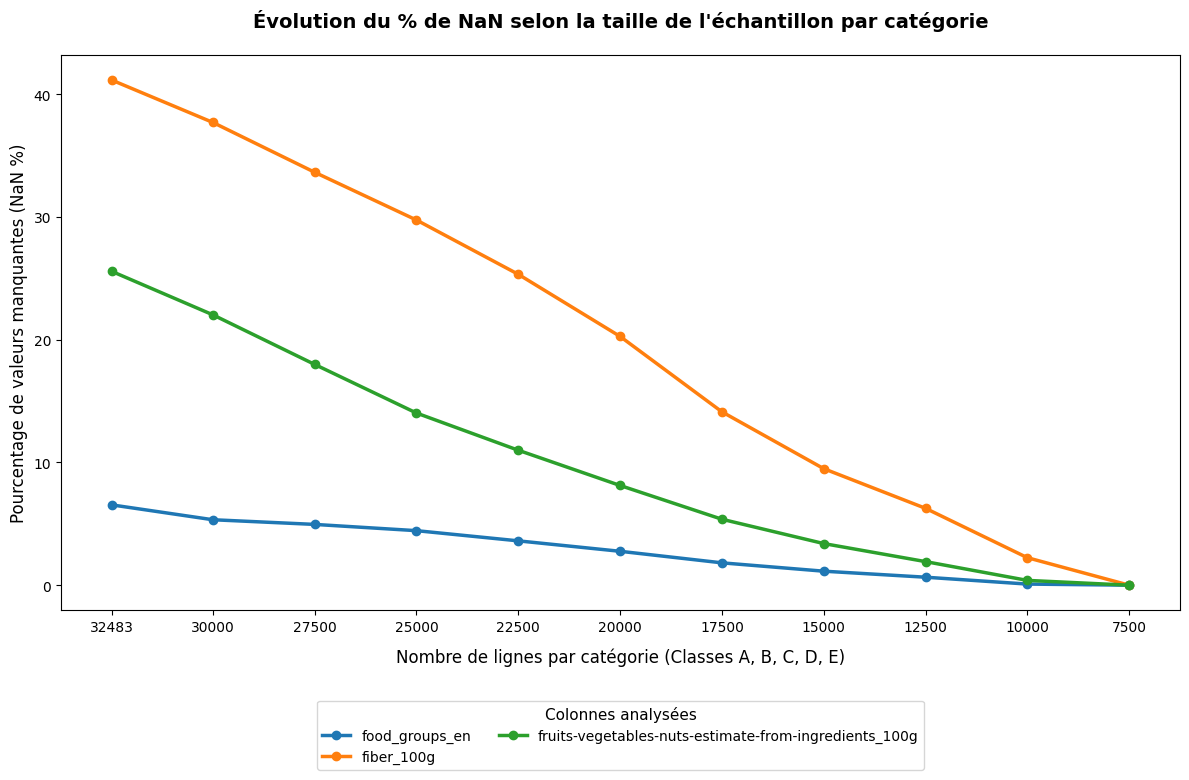

In [114]:
import matplotlib.pyplot as plt
# import seaborn as sns

# Configuration du style graphique
plt.figure(figsize=(12, 8))
# sns.set_theme(style="whitegrid")

# Inversion des colonnes pour avoir l'ordre croissant du nombre de lignes sur l'axe X
df_plot = df_comparatif_detaille.copy()
# On extrait uniquement le nombre de lignes par catégorie pour l'axe X (ex: '20000' depuis '20000/cat')
nb_lignes_categories = [int(col.split('/')[0]) for col in df_plot.columns]

# Tracer une courbe pour chaque colonne cible
for index, row in df_plot.iterrows():
    plt.plot(nb_lignes_categories, row.values, marker='o', linewidth=2.5, label=index)

# Personnalisation du graphique
plt.title("Évolution du % de NaN selon la taille de l'échantillon par catégorie", fontsize=14, fontweight='bold', pad=20)
plt.xlabel("Nombre de lignes par catégorie (Classes A, B, C, D, E)", fontsize=12, labelpad=10)
plt.ylabel("Pourcentage de valeurs manquantes (NaN %)", fontsize=12)
plt.xticks(nb_lignes_categories)
plt.gca().invert_xaxis()  # Garder la logique décroissante pour voir l'impact de la réduction

# Positionnement de la légende en dessous du graphique pour libérer de l'espace horizontal
plt.legend(
    title="Colonnes analysées",
    title_fontsize='11',
    loc='upper center',
    bbox_to_anchor=(0.5, -0.15),
    ncol=2,          # Disposer la légende sur 2 colonnes pour la compacité
    frameon=True
)

# Ajustement automatique des marges pour éviter que la légende sous le graphique ne soit coupée
plt.tight_layout()

# Affichage
plt.show()

## Étape 11 : Sélection Finale et Exportation du Dataset (62 500 Lignes)
Sur la base de notre graphique d'analyse de compromis, nous sélectionnons **12 500 lignes par catégorie** (soit un jeu final de **62 500 lignes**). Ce choix offre un excellent compromis en termes de volume de données tout en garantissant des taux de valeurs manquantes (NaN) faibles pour nos colonnes clés comme les fibres.

In [115]:
# Sélection stricte et directe de 12 500 lignes par catégorie et sauvegarde
target_size_final = 12500
balanced_chunks_final = []

# Calcul temporaire pour trier par complétude
df_france_final['nb_nan_ligne'] = df_france_final.isnull().sum(axis=1)

for cat in ['A', 'B', 'C', 'D', 'E']:
    df_cat = df_france_final[df_france_final['nutriscore_categorie'] == cat]
    df_cat_sampled = df_cat.sort_values(by='nb_nan_ligne', ascending=True).head(target_size_final)
    balanced_chunks_final.append(df_cat_sampled)

# Création du dataset final et suppression de la colonne temporaire
df_balanced_62k = pd.concat(balanced_chunks_final).sort_index()
df_balanced_62k = df_balanced_62k.drop(columns=['nb_nan_ligne'])

# Sauvegarde sous format CSV pour téléchargement
output_path = 'openfoodfacts_balanced_62k.csv'
df_balanced_62k.to_csv(output_path, index=False)

print(f"Fichier sauvegardé avec succès : {output_path} ({df_balanced_62k.shape[0]} lignes)")

Fichier sauvegardé avec succès : openfoodfacts_balanced_62k.csv (62500 lignes)


## Étape 12 : Entraînement du modèle
Maintenant que les données ont été nettoyées, nous pouvons maintenant passer à la construction de notre pipeline, c'est-à-dire la constuction de notre modèle.

In [116]:
import pandas as pd

file_path = './openfoodfacts_balanced_62k.csv'
df_cleaned = pd.read_csv(file_path)

In [117]:
df_cleaned.head()

,food_groups_en,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,fruits-vegetables-nuts-estimate-from-ingredients_100g,nutrition-score-fr_100g,nutriscore_categorie
0,"Sugary snacks,Sweets",465.0,39.5,6.0,41.0,40.2,NaN,0.0,0.20,0.000000,19.0,E
1,"Fruits and vegetables,Fruits",377.0,0.5,0.1,93.0,66.0,NaN,1.5,0.02,76.000000,1.0,B
2,"Cereals and potatoes,Cereals",240.0,1.6,0.3,47.0,0.2,NaN,8.3,1.14,0.358073,2.0,B
3,"Sugary snacks,Sweets",563.0,30.5,18.8,51.6,51.6,0.0,0.0,2.23,23.437500,36.0,E
4,"Fats and sauces,Dressings and sauces",408.0,37.0,4.0,17.0,12.0,0.2,1.7,2.20,0.000000,19.0,E


In [118]:
nan_counts_sub = df_cleaned.isna().sum().to_frame(name='Nombre de NaN')

# Calcul du pourcentage par rapport à ce sous-ensemble
nan_counts_sub['Pourcentage (%)'] = ((df_cleaned.isna().sum() / len(df_cleaned)) * 100).round(2)

display(nan_counts_sub)

,Nombre de NaN,Pourcentage (%)
food_groups_en,406,0.65
energy-kcal_100g,0,0.00
fat_100g,0,0.00
saturated-fat_100g,0,0.00
carbohydrates_100g,0,0.00
sugars_100g,0,0.00
fiber_100g,3913,6.26
proteins_100g,0,0.00
salt_100g,0,0.00
fruits-vegetables-nuts-estimate-from-ingredients_100g,1198,1.92


Pour la feature `food_groups_en`, on regroupe les 406 NaN dans le groupe 'Unknown', déjà présents dans nos données.

In [119]:
df_cleaned[df_cleaned['food_groups_en'] == 'Unknown']

,food_groups_en,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,fruits-vegetables-nuts-estimate-from-ingredients_100g,nutrition-score-fr_100g,nutriscore_categorie
758,Unknown,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.000000,0.0,B
14797,Unknown,4.0,0.0,0.0,0.5,0.50,0.0,0.5,0.0,8.550000,2.0,B
39881,Unknown,1.0,0.0,0.0,0.2,0.00,0.0,0.1,0.0,0.000000,1.0,B
51783,Unknown,4.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.000000,1.0,B
53042,Unknown,1.0,0.0,0.0,0.2,0.00,0.0,0.1,0.0,7.000000,1.0,B
60850,Unknown,1.0,0.0,0.0,0.2,0.13,0.0,0.0,0.0,NaN,2.0,B
61375,Unknown,4.0,0.0,0.0,0.5,0.50,NaN,0.5,0.0,20.666667,2.0,B
61395,Unknown,4.0,0.0,0.0,0.5,0.50,NaN,0.5,0.0,0.000000,2.0,B


Pour la feature `fruits-vegetables-nuts-estimate-from-ingredients_100g`, on a 1 198 NaN. On impute avec la moyenne du food_groups_en pour les variances raisonnables et on supprime le reste.

In [120]:
# Affichage des lignes NaN
df_cleaned[df_cleaned['fruits-vegetables-nuts-estimate-from-ingredients_100g'].isna()]

,food_groups_en,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,fruits-vegetables-nuts-estimate-from-ingredients_100g,nutrition-score-fr_100g,nutriscore_categorie
50,"Composite foods,Sandwiches",201.0,4.7,1.90,28.9,2.1,1.4,10.90,1.20,NaN,2.0,B
52,"Composite foods,Sandwiches",209.0,7.5,0.59,29.0,2.4,4.3,5.63,1.59,NaN,2.0,B
54,"Cereals and potatoes,Cereals",140.0,11.0,0.90,7.2,6.4,2.7,1.00,0.60,NaN,2.0,B
57,"Sugary snacks,Pastries",53.0,0.0,0.00,12.4,10.7,0.7,0.50,0.10,NaN,2.0,B
58,"Cereals and potatoes,Bread",277.0,5.0,0.50,48.0,6.5,5.4,7.40,1.50,NaN,1.0,B
...,...,...,...,...,...,...,...,...,...,...,...,...
62493,"Fats and sauces,Dressings and sauces",512.0,33.0,3.00,46.0,14.0,2.5,4.40,5.90,NaN,19.0,E
62494,"Fish‚ Meat‚ Eggs,Processed meat",110.0,2.0,0.80,0.9,0.5,0.5,22.00,1.30,NaN,1.0,B
62495,"Fish‚ Meat‚ Eggs,Meat,Poultry",203.0,10.0,2.00,14.0,0.9,0.7,14.00,0.99,NaN,2.0,B
62496,"Sugary snacks,Sweets",107.0,5.3,2.70,11.0,7.0,3.4,2.10,0.02,NaN,0.0,B


In [121]:
import pandas as pd

# Définition de la colonne cible ainsi que du seuil d’écart-type
col = 'fruits-vegetables-nuts-estimate-from-ingredients_100g'
std_threshold = 30.0  # A ajuster

# 1. Calcule de l’écart-type et de la moyenne pour chaque groupe alimentaire
group_stats = df_cleaned.groupby('food_groups_en')[col].agg(['std', 'mean'])

# 2. Filtrage pour ne conserver que les moyennes des groupes dont l'écart-type est inférieur au seuil
# (Si un groupe ne contient qu'une seule valeur, l'écart-type est NaN ; il sera donc automatiquement exclu)
low_std_means = group_stats[group_stats['std'] < std_threshold]['mean']

# 3. Créez une série qui associe ces moyennes « sûres » à chaque ligne du jeu de données.
mapped_safe_means = df_cleaned['food_groups_en'].map(low_std_means)

# 4. Remplacement des valeurs NaN par des moyennes fiables, lorsque cela est possible
df_cleaned[col] = df_cleaned[col].fillna(mapped_safe_means)


In [122]:
# Analyse statistique de deux groupes de fruits et légumes pour la colonne 'fruits-vegetables-nuts-estimate-from-ingredients_100g'
mask = (
    (df_cleaned['food_groups_en'] == 'Fruits and vegetables,Dried fruits') |
    (df_cleaned['food_groups_en'] == 'Fruits and vegetables,Fruits')
)
df_cleaned[mask].groupby('food_groups_en')['fruits-vegetables-nuts-estimate-from-ingredients_100g'].describe()

,count,mean,std,min,25%,50%,75%,max
food_groups_en,,,,,,,,
"Fruits and vegetables,Dried fruits",1170.0,65.521567,37.645620,0.0,50.000000,75.0,100.0,100.0
"Fruits and vegetables,Fruits",1706.0,74.036778,35.620089,0.0,61.151786,94.0,99.9,100.0


In [123]:
nan_counts_sub = df_cleaned.isna().sum().to_frame(name='Nombre de NaN')

# Calcul du pourcentage par rapport à ce sous-ensemble
nan_counts_sub['Pourcentage (%)'] = ((df_cleaned.isna().sum() / len(df_cleaned)) * 100).round(2)

display(nan_counts_sub)

,Nombre de NaN,Pourcentage (%)
food_groups_en,406,0.65
energy-kcal_100g,0,0.00
fat_100g,0,0.00
saturated-fat_100g,0,0.00
carbohydrates_100g,0,0.00
sugars_100g,0,0.00
fiber_100g,3913,6.26
proteins_100g,0,0.00
salt_100g,0,0.00
fruits-vegetables-nuts-estimate-from-ingredients_100g,205,0.33


Enfin, pour la feature `fiber_100g`, parce qu'elle est essentielle pour le calcul du Nutri-Score, on va laisser notre pipeline gérer les NaN lors de son apprentissage. L'objectif est qu'en cas de données manquantes sur les fibres, le modèle devrait davantage s'intéresser aux carbohydrates et sucres pour son estimation.

In [124]:
df_cleaned['food_groups_en'] = df_cleaned['food_groups_en'].fillna('Unknown')
df_cleaned = df_cleaned[df_cleaned['fruits-vegetables-nuts-estimate-from-ingredients_100g'].notna()]

## Étape 13 : Construction de la pipeline

In [125]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# 1. Charger le jeu de données
df = df_cleaned.copy()  # Utiliser le jeu de données nettoyé et équilibré

# 2. Définir les variables explicatives (features) et la cible (target)
target = 'nutrition-score-fr_100g'
features = [
    'energy-kcal_100g',
    'saturated-fat_100g',
    'sugars_100g',
    'carbohydrates_100g', # Conservé pour aider le modèle à inférer les fibres manquantes
    'fiber_100g',         # Contient des valeurs manquantes (NaNs)
    'proteins_100g',
    'salt_100g',
    'fruits-vegetables-nuts-estimate-from-ingredients_100g',
    'food_groups_en'      # Variable catégorielle
]

# Supprimer les lignes où la cible (target) est manquante (impossible d'entraîner sur une réponse manquante)
df = df.dropna(subset=[target])

# Séparer le jeu de données en variables explicatives (X) et cible (y)
X = df[features]
y = df[target]

# 3. Division en ensembles d'entraînement et de test (80% entraînement, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Configuration du prétraitement
# Les algorithmes de boosting nécessitent que le texte catégoriel (food_groups_en) soit encodé numériquement.
# Toutes les autres colonnes numériques (y compris fiber_100g avec ses NaNs) sont transmises sans modification
# pour que l'algorithme de boosting puisse gérer nativement les valeurs manquantes.
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), ['food_groups_en'])
    ],
    remainder='passthrough'
)

# 5. Définir le modèle
# categorical_features=[0] indique au modèle que la PREMIÈRE colonne issue du préprocesseur
# (qui est food_groups_en) doit être traitée via des séparations catégorielles natives et non comme des nombres continus.
model = HistGradientBoostingRegressor(
    categorical_features=[0],
    random_state=42,
    max_iter=200 # Nombre d'arbres
)

# 6. Construire le pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', model)
])

# 7. Validation croisée sur les données d'entraînement
# Utilisation de KFold pour évaluer la stabilité du modèle sur 5 partitions différentes des données d'entraînement
print("Exécution de la validation croisée à 5 plis...")
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Calcul de l'erreur quadratique moyenne négative, puis conversion en racine de l'erreur quadratique moyenne (RMSE)
cv_scores = cross_val_score(pipeline, X_train, y_train, cv=kf, scoring='neg_mean_squared_error')
cv_rmse = np.sqrt(-cv_scores)

print(f"RMSE de validation croisée pour chaque pli : {cv_rmse}")
print(f"RMSE moyenne de validation croisée : {cv_rmse.mean():.2f} points de Nutri-Score\n")

# 8. Entraînement final et évaluation sur l'ensemble de test
print("Entraînement du modèle final sur l'ensemble complet...")
pipeline.fit(X_train, y_train)

# Prédiction sur l'ensemble de test non vu
test_predictions = pipeline.predict(X_test)

# Calcul des métriques finales
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)

print(f"RMSE finale sur le test : {test_rmse:.2f} points de Nutri-Score")
print(f"Score R² final sur le test : {test_r2:.3f} (plus proche de 1.0, meilleur c'est)")

Exécution de la validation croisée à 5 plis...
RMSE de validation croisée pour chaque pli : [0.97135924 1.01941409 0.98799172 1.00434609 0.97805999]
RMSE moyenne de validation croisée : 0.99 points de Nutri-Score

Entraînement du modèle final sur l'ensemble complet...
RMSE finale sur le test : 1.03 points de Nutri-Score
Score R² final sur le test : 0.989 (plus proche de 1.0, meilleur c'est)


# Étape 14 : Évaluation du modèle en classes Nutri-Score (A à E)

## Pourquoi cette étape ?
À l'étape 13, nous avons évalué le modèle avec le **RMSE** et le **R²**. Ces métriques mesurent l'écart sur le score brut (de -15 à +40). Or, ce qui compte pour un consommateur, c'est la **lettre** affichée sur l'emballage (A, B, C, D ou E). Une erreur de 1 point peut être sans conséquence ou changer la lettre, selon que le score est au milieu d'une tranche ou à une frontière (par exemple 2 → B, 3 → C).

Nous convertissons donc les prédictions du modèle en classes avec **les mêmes seuils que ceux des étiquettes**, puis nous évaluons le modèle comme un classifieur.

## Les métriques utilisées
*   **Exactitude (accuracy)** : proportion de produits dont la lettre est exactement la bonne.
*   **F1 macro** : moyenne des F1 de chaque classe. Elle donne le même poids à A, B, C, D et E, ce qui est cohérent avec notre jeu de données équilibré.
*   **Exactitude à ±1 classe** : proportion de produits dont la lettre prédite est la bonne ou une lettre voisine. Elle montre si les erreurs sont « graves » (A prédit à la place de E) ou « proches » (B prédit à la place de C).
*   **Matrice de confusion** : montre quelles classes sont confondues entre elles. Les erreurs se concentrent normalement aux frontières entre classes voisines.

## Précaution
Le modèle prédit un nombre à virgule. Avant de le convertir en lettre, nous l'**arrondissons à l'entier le plus proche**, car le score officiel est un entier. Les seuils sont ceux de l'étape 4 : A ≤ -1, B de 0 à 2, C de 3 à 10, D de 11 à 18, E ≥ 19.

=== Évaluation en classes Nutri-Score ===
Exactitude (classe exacte)       : 92.977%
F1 macro                         : 0.930
Exactitude à ±1 classe           : 99.823%
Erreurs de 2 classes ou plus     : 22 produits sur 12459

=== Rapport par classe ===
              precision    recall  f1-score   support

           A      0.961     0.953     0.957      2514
           B      0.918     0.885     0.901      2434
           C      0.866     0.934     0.899      2571
           D      0.935     0.902     0.918      2436
           E      0.976     0.972     0.974      2504

    accuracy                          0.930     12459
   macro avg      0.931     0.929     0.930     12459
weighted avg      0.931     0.930     0.930     12459



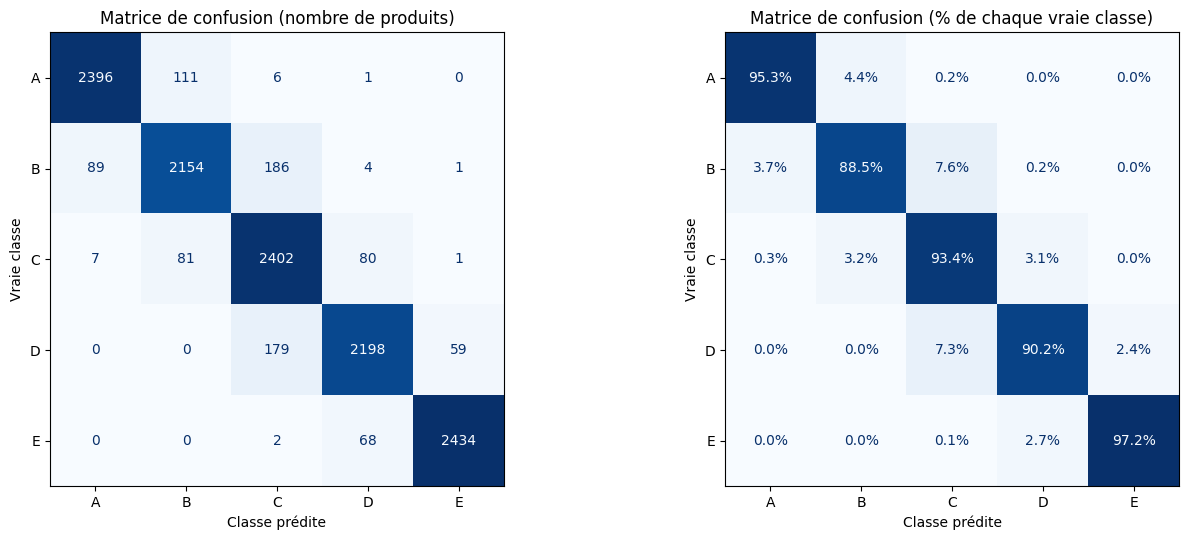


Nombre total d'erreurs de classe : 875 (7.02% du jeu de test)
Erreurs par vraie classe :
  A : 118 erreurs sur 2514 produits (4.7%)
  B : 280 erreurs sur 2434 produits (11.5%)
  C : 169 erreurs sur 2571 produits (6.6%)
  D : 238 erreurs sur 2436 produits (9.8%)
  E : 70 erreurs sur 2504 produits (2.8%)


In [126]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

LABELS = ['A', 'B', 'C', 'D', 'E']

# 1. Conversion des vraies valeurs et des prédictions en classes
y_test_classes = y_test.apply(attribuer_categorie).values
y_pred_classes = pd.Series(np.round(test_predictions)).apply(attribuer_categorie).values

# 2. Métriques globales
accuracy = accuracy_score(y_test_classes, y_pred_classes)
f1_macro = f1_score(y_test_classes, y_pred_classes, average='macro', labels=LABELS)

# Exactitude à ±1 classe : on compare les positions des lettres (A=0, ..., E=4)
pos_vraie = np.array([LABELS.index(c) for c in y_test_classes])
pos_pred = np.array([LABELS.index(c) for c in y_pred_classes])
acc_plus_moins_1 = np.mean(np.abs(pos_vraie - pos_pred) <= 1)

print("=== Évaluation en classes Nutri-Score ===")
print(f"Exactitude (classe exacte)       : {accuracy:.3%}")
print(f"F1 macro                         : {f1_macro:.3f}")
print(f"Exactitude à ±1 classe           : {acc_plus_moins_1:.3%}")
print(f"Erreurs de 2 classes ou plus     : {np.sum(np.abs(pos_vraie - pos_pred) >= 2)} produits "
      f"sur {len(y_test_classes)}\n")

# 3. Détail par classe (précision, rappel, F1)
print("=== Rapport par classe ===")
print(classification_report(y_test_classes, y_pred_classes, labels=LABELS, digits=3))

# 4. Matrice de confusion (effectifs et pourcentages par ligne)
cm = confusion_matrix(y_test_classes, y_pred_classes, labels=LABELS)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(
    ax=axes[0], cmap='Blues', colorbar=False, values_format='d'
)
axes[0].set_title("Matrice de confusion (nombre de produits)")
axes[0].set_xlabel("Classe prédite")
axes[0].set_ylabel("Vraie classe")

ConfusionMatrixDisplay.from_predictions(
    y_test_classes, y_pred_classes, labels=LABELS,
    normalize='true', cmap='Blues', colorbar=False,
    values_format='.1%', ax=axes[1]
)
axes[1].set_title("Matrice de confusion (% de chaque vraie classe)")
axes[1].set_xlabel("Classe prédite")
axes[1].set_ylabel("Vraie classe")

plt.tight_layout()
plt.show()

# 5. Où sont les erreurs ? Distance au seuil le plus proche
erreurs = y_test_classes != y_pred_classes
print(f"\nNombre total d'erreurs de classe : {erreurs.sum()} "
      f"({erreurs.mean():.2%} du jeu de test)")
print("Erreurs par vraie classe :")
for lettre in LABELS:
    masque = y_test_classes == lettre
    print(f"  {lettre} : {erreurs[masque].sum()} erreurs sur {masque.sum()} produits "
          f"({erreurs[masque].mean():.1%})")

## Interprétation des résultats
*   Une exactitude élevée et un F1 macro proche de l'exactitude indiquent que le modèle ne favorise pas une classe au détriment des autres, ce qui est attendu puisque notre jeu est équilibré.
*   L'**exactitude à ±1 classe** est presque parfaite : quand le modèle se trompe, il choisit une lettre voisine. Il ne confond pas un produit très bon avec un produit très mauvais.
*   La matrice de confusion montre que les erreurs se situent **quasi exclusivement entre classes adjacentes** (seulement 22 produits sur 12 459 sont à 2 classes d’écart ou plus) (A↔B, B↔C, C↔D, D↔E). C'est logique : un produit dont le score réel est 2 (classe B) et que le modèle prédit à 2,6 (arrondi à 3) passe en classe C, alors que l'écart n'est que de 1 point.
*   Les classes du milieu (B, C, D) sont les plus difficiles, car elles ont une frontière de chaque côté, alors que A et E n'en ont qu'une.

## Limites
*   Ces résultats portent sur un jeu **équilibré** et **dédoublonné** (12 500 produits par classe). Dans la réalité, les classes ne sont pas équilibrées, donc les performances sur l'ensemble des produits vendus pourraient être légèrement différentes.
*   Les boissons ont un barème de Nutri-Score différent de celui des aliments : elles ont été exclues à l'étape 3, donc le modèle ne les couvre pas.